# 02 — Dataset Build & Exploratory Data Analysis (2,507 LA Tiles)

This notebook inspects how our Phase 4 dataset (`data/processed/urban_heat_tiles.csv`) was assembled from **36 FortyGuard heatmaps** and enriched with **free OpenStreetMap + geographic features** (**0 API credits** to run).

It covers:
1. Data provenance (`manifest.json` — reused smoke tests vs. Phase 4 collection)
2. Schema, missing-value, and duplicate checks (`2,507` rows × `24` columns)
3. Spatial heat map of all `2,507` tiles across the Los Angeles Basin
4. Feature correlations: macro-geography (`dist_to_coast_km`, `elevation_m`) vs. local urban form (`osm_*`)
5. Within-neighborhood temperature anomaly preview & anti-leakage guardrails for ML

In [7]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("..") if Path("../data/processed/urban_heat_tiles.csv").exists() else Path(".")
manifest = json.loads((BASE / "data/raw/phase4_heatmaps/manifest.json").read_text(encoding="utf-8"))
df = pd.read_csv(BASE / "data/processed/urban_heat_tiles.csv")

print(f"Manifest neighborhoods: {manifest['total_neighborhoods']} | Expected tiles: {manifest['total_tiles']}")
print(f"Loaded CSV shape: {df.shape}")

Manifest neighborhoods: 36 | Expected tiles: 2507
Loaded CSV shape: (2507, 24)


## 1. Data Provenance & Quality Checks
Let's verify that we have zero missing values, zero duplicate tile IDs, and see how neighborhoods break down by source and LA zone.

In [8]:
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate tile_uid count:", df["tile_uid"].duplicated().sum())
print("\nTiles by source:\n", df["source"].value_counts())
print("\nTiles by zone:\n", df["zone"].value_counts())

Missing values per column:
 Series([], dtype: int64)
Duplicate tile_uid count: 0

Tiles by source:
 source
phase4_collection    2354
phase3_mcp_test        81
phase2_smoke_test      72
Name: count, dtype: int64

Tiles by zone:
 zone
westside              273
valley                266
coastal               233
central_east          200
urban_core            194
south_la              193
sgv_foothills         153
sgv                   153
foothills             147
industrial            121
south_bay              84
central                83
park_hills             81
coastal_industrial     81
valley_industrial      74
harbor                 72
harbor_industrial      54
west_valley            45
Name: count, dtype: int64


## 2. Spatial Temperature Map & Distribution (20.72 °C to 36.99 °C)
Plotting every tile's `(centroid_lon, centroid_lat)` colored by FortyGuard `average_temperature` makes the LA Basin's geography jump off the page: cool ocean air on the west/south coast, warming sharply into the San Fernando & San Gabriel Valleys.

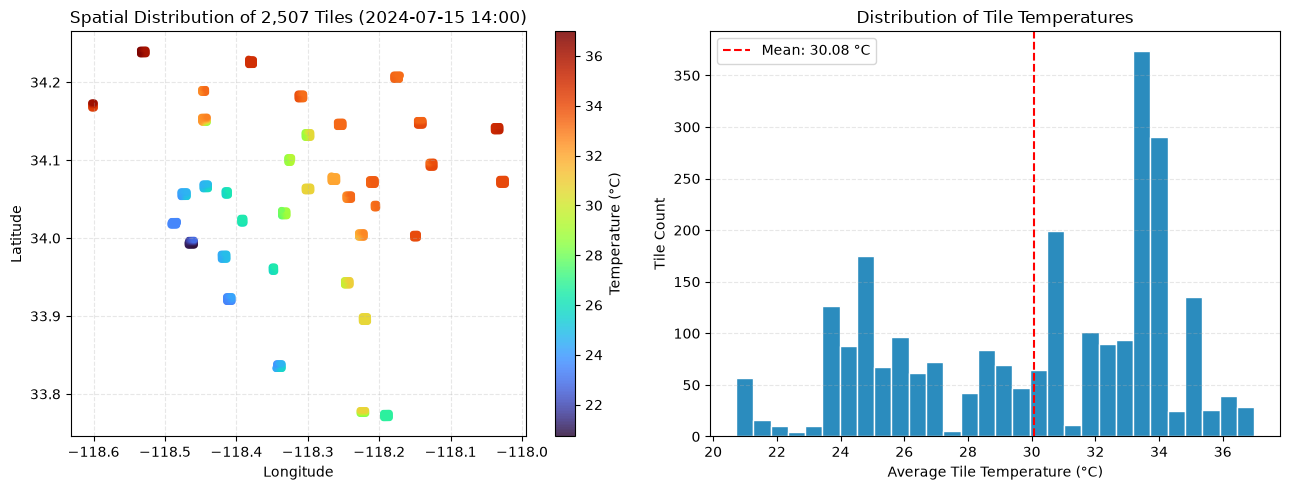

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sc = axes[0].scatter(
    df["centroid_lon"], df["centroid_lat"],
    c=df["average_temperature"], cmap="turbo", s=12, alpha=0.85
)
plt.colorbar(sc, ax=axes[0], label="Temperature (°C)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_title("Spatial Distribution of 2,507 Tiles (2024-07-15 14:00)")
axes[0].grid(True, linestyle="--", alpha=0.3)

axes[1].hist(df["average_temperature"], bins=30, color="#2b8cbe", edgecolor="white")
axes[1].axvline(df["average_temperature"].mean(), color="red", linestyle="--", label=f"Mean: {df['average_temperature'].mean():.2f} °C")
axes[1].set_xlabel("Average Tile Temperature (°C)")
axes[1].set_ylabel("Tile Count")
axes[1].set_title("Distribution of Tile Temperatures")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### 2b. Geographic Map View of the LA Basin (with Coastline & Landmark Labels)
To make the spatial layout easier to read like a real map (without needing extra map-tile libraries), we draw the Southern California coastline, shade the Pacific Ocean, preserve true geographic aspect ratio, and label key contrasting neighborhoods alongside a regional boxplot of temperature.

C:\Users\Kamiye\AppData\Local\Temp\ipykernel_14808\1190379857.py:55: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(zone_data, vert=False, tick_labels=[z.replace("_", " ") for z in zone_order], patch_artist=True,


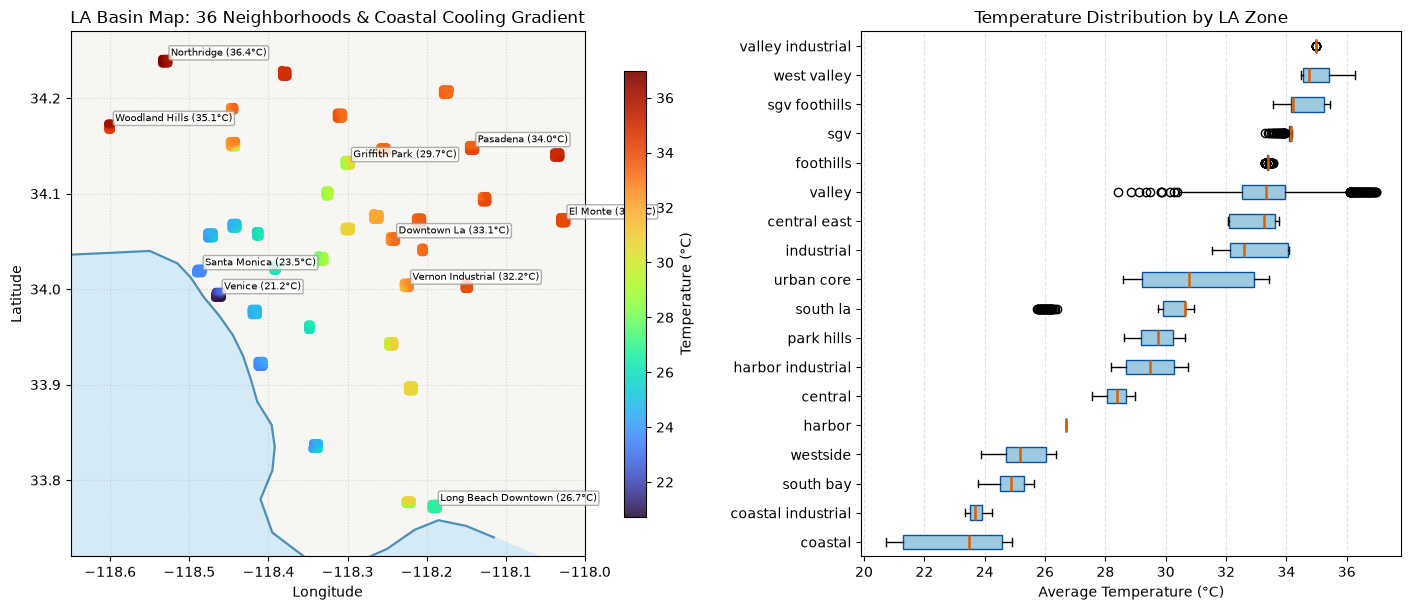

In [9]:
coast_pts = np.array([
    [-118.680, 34.035], [-118.600, 34.038], [-118.550, 34.040],
    [-118.515, 34.027], [-118.498, 34.012], [-118.482, 33.992],
    [-118.462, 33.972], [-118.445, 33.952], [-118.432, 33.930],
    [-118.422, 33.905], [-118.414, 33.882], [-118.396, 33.858],
    [-118.392, 33.835], [-118.395, 33.810], [-118.410, 33.780],
    [-118.395, 33.745], [-118.355, 33.720], [-118.315, 33.708],
    [-118.285, 33.715], [-118.250, 33.728], [-118.215, 33.748],
    [-118.185, 33.758], [-118.150, 33.752], [-118.115, 33.740],
])
ocean_poly = np.vstack([coast_pts, [[-118.00, 33.70], [-118.68, 33.70], [-118.68, 34.035]]])

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.45, 1.0]})

# Left: Map-like LA Basin view
ax = axes[0]
ax.set_facecolor("#f7f6f2")
ax.fill(ocean_poly[:, 0], ocean_poly[:, 1], color="#d4eaf7", zorder=1, label="Pacific Ocean")
ax.plot(coast_pts[:, 0], coast_pts[:, 1], color="#4a90b8", linewidth=1.6, zorder=2)

sc = ax.scatter(
    df["centroid_lon"], df["centroid_lat"],
    c=df["average_temperature"], cmap="turbo", s=18, alpha=0.9, zorder=3
)
plt.colorbar(sc, ax=ax, shrink=0.85, label="Temperature (°C)")

landmarks = [
    "venice", "santa_monica", "downtown_la", "griffith_park",
    "vernon_industrial", "pasadena", "northridge", "woodland_hills",
    "long_beach_downtown", "el_monte"
]
nb_centers = df.groupby("neighborhood")[["centroid_lon", "centroid_lat", "average_temperature"]].mean()
for slug in landmarks:
    if slug in nb_centers.index:
        row = nb_centers.loc[slug]
        label = f"{slug.replace('_', ' ').title()} ({row['average_temperature']:.1f}°C)"
        ax.annotate(
            label, (row["centroid_lon"], row["centroid_lat"]),
            xytext=(4, 4), textcoords="offset points", fontsize=7.5,
            bbox=dict(boxstyle="round,pad=0.18", facecolor="white", alpha=0.78, edgecolor="#999"),
            zorder=4,
        )

ax.set_xlim(-118.65, -118.00)
ax.set_ylim(33.72, 34.27)
ax.set_aspect(1.0 / np.cos(np.radians(34.05)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("LA Basin Map: 36 Neighborhoods & Coastal Cooling Gradient")
ax.grid(True, linestyle=":", alpha=0.45)

# Right: Temperature distribution by zone
zone_order = df.groupby("zone")["average_temperature"].median().sort_values().index.tolist()
zone_data = [df.loc[df["zone"] == z, "average_temperature"].to_numpy() for z in zone_order]
axes[1].boxplot(zone_data, vert=False, tick_labels=[z.replace("_", " ") for z in zone_order], patch_artist=True,
                boxprops=dict(facecolor="#9ecae1", color="#08519c"),
                medianprops=dict(color="#d95f02", linewidth=1.8))
axes[1].set_xlabel("Average Temperature (°C)")
axes[1].set_title("Temperature Distribution by LA Zone")
axes[1].grid(axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

## 3. Feature Correlations with Temperature
Before training any ML model, let's check both Pearson (linear) and Spearman (monotonic/rank) correlations against `average_temperature`.

In [10]:
feature_cols = [
    "dist_to_coast_km", "dist_to_dtla_km", "elevation_m",
    "osm_building_pct", "osm_building_count", "osm_road_length_m", "osm_major_road_m",
    "osm_green_pct", "osm_water_pct", "osm_industrial_comm_pct",
    "osm_residential_pct", "osm_parking_pct",
]

corr_df = pd.DataFrame({
    "pearson_r": [df[c].corr(df["average_temperature"], method="pearson") for c in feature_cols],
    "spearman_rho": [df[c].corr(df["average_temperature"], method="spearman") for c in feature_cols],
}, index=feature_cols).sort_values("spearman_rho", key=abs, ascending=False)

corr_df.round(4)

,pearson_r,spearman_rho
dist_to_coast_km,0.8648,0.8776
elevation_m,0.5407,0.6392
osm_building_count,-0.2737,-0.2417
osm_building_pct,-0.1168,-0.1415
osm_residential_pct,-0.1413,-0.1410
dist_to_dtla_km,-0.1949,-0.1252
osm_major_road_m,0.1015,0.1223
osm_industrial_comm_pct,0.1211,0.1135
osm_green_pct,-0.0298,-0.0922
osm_water_pct,-0.0270,-0.0248


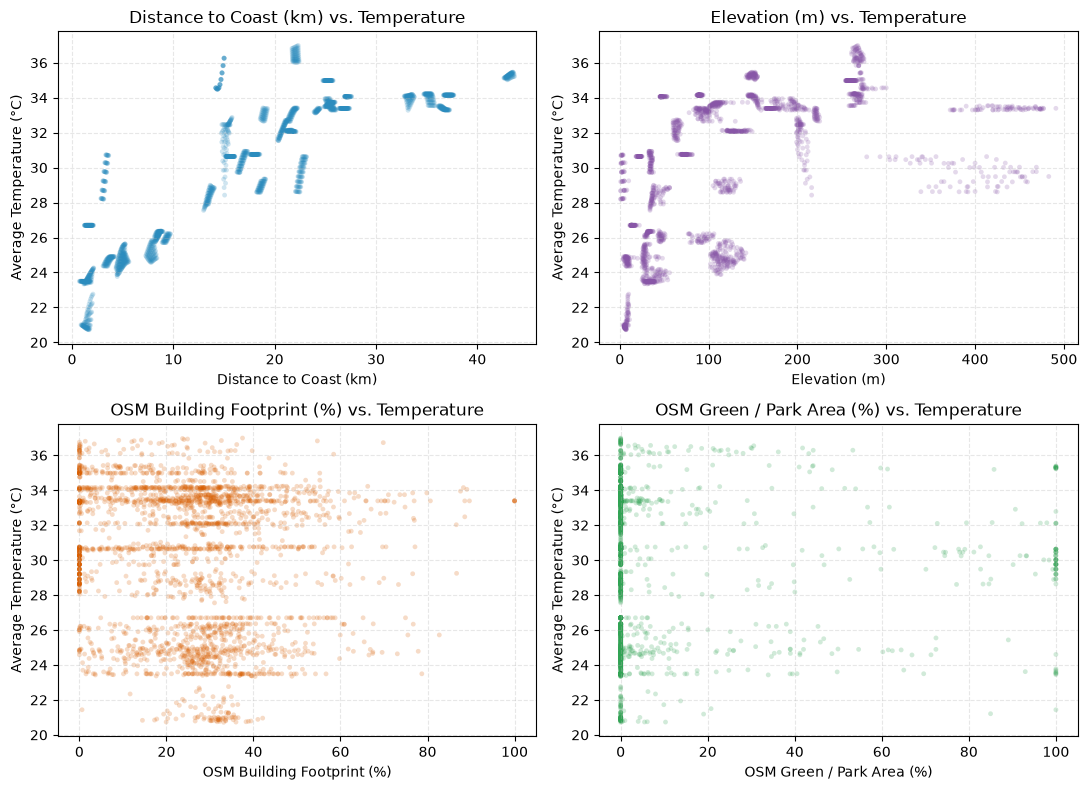

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
pairs = [
    ("dist_to_coast_km", "Distance to Coast (km)", "#2b8cbe"),
    ("elevation_m", "Elevation (m)", "#8856a7"),
    ("osm_building_pct", "OSM Building Footprint (%)", "#d95f02"),
    ("osm_green_pct", "OSM Green / Park Area (%)", "#31a354"),
]
for ax, (col, label, color) in zip(axes.ravel(), pairs):
    ax.scatter(df[col], df["average_temperature"], alpha=0.22, s=12, color=color, edgecolors="none")
    ax.set_xlabel(label)
    ax.set_ylabel("Average Temperature (°C)")
    ax.set_title(f"{label} vs. Temperature")
    ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Within-Neighborhood Temperature Anomaly (Micro-Scale Preview)
Because the coastal-to-valley gradient spans ~15 °C across LA, let's also look at **local temperature anomaly** (`tile_temp - neighborhood_mean_temp`). That strips out macro-geography and reveals whether local buildings, roads, and parks explain block-to-block heat *within* the same neighborhood.

In [12]:
df["temp_anomaly_c"] = df["average_temperature"] - df.groupby("neighborhood")["average_temperature"].transform("mean")
print("Within-neighborhood anomaly std:", round(df["temp_anomaly_c"].std(), 4), "°C")
print("Range:", round(df["temp_anomaly_c"].min(), 3), "to", round(df["temp_anomaly_c"].max(), 3), "°C")

osm_cols = [c for c in feature_cols if c.startswith("osm_")]
anom_corr = pd.Series({c: df[c].corr(df["temp_anomaly_c"], method="spearman") for c in osm_cols}).sort_values(key=abs, ascending=False)
anom_corr.round(4)

Within-neighborhood anomaly std: 0.3544 °C
Range: -3.3 to 1.515 °C


osm_residential_pct        0.1727
osm_industrial_comm_pct    0.0753
osm_road_length_m         -0.0470
osm_major_road_m          -0.0359
osm_parking_pct           -0.0359
osm_water_pct              0.0354
osm_green_pct              0.0223
osm_building_pct          -0.0076
osm_building_count         0.0070
dtype: float64

## 5. Anti-Leakage Guardrails for Notebook 03
* **Target (`y`):** `average_temperature` (and secondary micro-heat target `temp_anomaly_c`).
* **Excluded from `X` (leakage / identifiers):** `min_temperature`, `max_temperature`, `tile_uid`, `tile_id`, `neighborhood`, `neighborhood_name`, `zone`, `source`, `centroid_lat`, `centroid_lon`, `tile_area_m2`.
* **Validation group:** `neighborhood` (`36` groups) via 5-fold `GroupKFold`, so nearby 100m tiles never leak across train and test folds.